Detected PSD peaks
-------------------------------------------------------
Signal  Band      Frequency (Hz)    Power (dB)
Bio     Theta              10.50         -7.86
Bio     Gamma              33.00        -21.51
BNC     Theta              10.00         -7.20
BNC     Gamma              35.50        -21.37


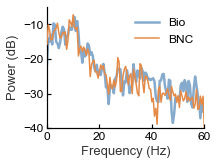

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import os
from scipy.signal import find_peaks

# ==========================================
# 1. Global font and axis styling
# ==========================================
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']
mpl.rcParams['axes.edgecolor'] = 'black'
mpl.rcParams['axes.linewidth'] = 1.2
mpl.rcParams['xtick.color'] = 'black'
mpl.rcParams['ytick.color'] = 'black'

# Explicitly enable inward-facing ticks
mpl.rcParams['xtick.direction'] = 'in'
mpl.rcParams['ytick.direction'] = 'in'
mpl.rcParams['xtick.bottom'] = True
mpl.rcParams['ytick.left'] = True
mpl.rcParams['xtick.major.width'] = 1.2
mpl.rcParams['ytick.major.width'] = 1.2
mpl.rcParams['xtick.major.size'] = 4.0
mpl.rcParams['ytick.major.size'] = 4.0
mpl.rcParams.update({'svg.fonttype': 'none', 'pdf.fonttype': 42})

plt.rcParams.update({
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    'font.size': 8+5,          # Default text
    'axes.titlesize': 8+5,     # Title
    'axes.labelsize': 8+5,     # Axis labels
    'xtick.labelsize': 7+5,    # X-axis tick labels
    'ytick.labelsize': 7+5,    # Y-axis tick labels
    'legend.fontsize': 7+5,    # Legend
    'figure.titlesize': 9+5,   # Figure-level title
})

# Define the muted color palette
color_bio = '#5C8EBC'  # Muted blue
color_hw = '#E58A46'   # Warm orange

# define function
def detect_band_peak(freqs, psd_db, band, min_prominence_db=0.5):
    """Return the dominant local PSD peak within a frequency band."""
    low, high = band
    band_mask = (freqs >= low) & (freqs <= high)
    band_indices = np.flatnonzero(band_mask)
    if band_indices.size == 0:
        raise ValueError(f'No frequency bins found between {low} and {high} Hz.')

    band_power = psd_db[band_mask]
    local_peaks, properties = find_peaks(
        band_power, prominence=min_prominence_db
    )

    # Use the strongest local peak; fall back to the band maximum if needed.
    if local_peaks.size:
        local_peak = local_peaks[np.argmax(band_power[local_peaks])]
    else:
        local_peak = int(np.argmax(band_power))

    peak_index = band_indices[local_peak]
    return {
        'frequency': float(freqs[peak_index]),
        'power_db': float(psd_db[peak_index]),
        'index': int(peak_index),
    }

# ==========================================
# 2. Load data
# ==========================================
filedir = './figures/'
os.makedirs(filedir, exist_ok=True)

# Load the PSD data from the configured paths
try:
    filepath1 = "../Simulations_Data/rand3/rand_Bio1/out/"
    data1 = np.load(filepath1 + 'psd_data.npz')
    freqs1 = data1['freqs']
    psd_db1 = 10 * np.log10(data1['psd'] + 1e-12)

    filepath2 = "../Simulations_Data/rand3/rand_hard1/out/"
    data2 = np.load(filepath2 + 'psd_data.npz')
    freqs2 = data2['freqs']
    psd_db2 = 10 * np.log10(data2['psd'] + 1e-12)
except Exception as e:
    print(f"Failed to load data. Please verify the paths: {e}")
    # Stop execution if the required data cannot be loaded
    exit()

# ==========================================
# 3. Detect the dominant theta and gamma peaks
# ==========================================
frequency_bands = {
    'Theta': (4.0, 12.0),
    'Gamma': (30.0, 60.0),
}

peak_results = {'Bio': {}, 'BNC': {}}
for band_name, band_limits in frequency_bands.items():
    peak_results['Bio'][band_name] = detect_band_peak(
        freqs1, psd_db1, band_limits
    )
    peak_results['BNC'][band_name] = detect_band_peak(
        freqs2, psd_db2, band_limits
    )

print('Detected PSD peaks')
print('-' * 55)
print(f"{'Signal':<8}{'Band':<8}{'Frequency (Hz)':>16}{'Power (dB)':>14}")
for signal_name in ('Bio', 'BNC'):
    for band_name in frequency_bands:
        result = peak_results[signal_name][band_name]
        print(
            f"{signal_name:<8}{band_name:<8}"
            f"{result['frequency']:>16.2f}{result['power_db']:>14.2f}"
        )

# ==========================================
# 4. Plot the PSD comparison and detected peaks
# ==========================================
fig, ax = plt.subplots(1, 1, figsize=(2.8*1.15, 5.4* 0.8 / 2*1.15))

# Core visual treatment: nested line widths and transparency
# 1. Draw Bio as the wider, slightly translucent base layer (zorder=2)
ax.plot(freqs1, psd_db1, color=color_bio, linewidth=2.5, alpha=0.75, label='Bio', zorder=2)

# 2. Draw BNC as a narrower, opaque validation layer above Bio (zorder=3)
# When the curves agree, the orange line remains visible along the center of the blue trace.
ax.plot(freqs2, psd_db2, color=color_hw, linewidth=1.5, alpha=1.0, label='BNC', zorder=3)

# Mark the detected theta and gamma peaks.
# signal_styles = {
#     'Bio': {'color': color_bio, 'marker': 'o'},
#     'BNC': {'color': color_hw, 'marker': 's'},
# }
# for signal_name, style in signal_styles.items():
#     for band_name, result in peak_results[signal_name].items():
#         peak_frequency = result['frequency']
#         peak_power = result['power_db']
#         ax.scatter(
#             peak_frequency, peak_power, s=32, marker=style['marker'],
#             facecolor='white', edgecolor=style['color'], linewidth=1.4,
#             zorder=5
#         )

# ==========================================
# 5. Axis styling and output
# ==========================================
ax.set_xlabel('Frequency (Hz)', color='#333333')
ax.set_ylabel('Power (dB)',  color='#333333')

# Axis limits
ax.set_xlim([0, 60])
ax.set_ylim([-40, -5])

# Hide the top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Place the legend inside the upper-right low-power region
ax.legend(loc='upper right', frameon=False)

plt.tight_layout()
plt.savefig(os.path.join(filedir, 'psd_compare_i1j3_optimized.svg'), dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(filedir, 'psd_compare_i1j3_optimized.png'), dpi=300, bbox_inches='tight')
plt.show()